# Loan default modeling

I’m starting with the date range and status mix before I pick a cutoff. The first thing I want to see is how much of the tail of the dataset is actually usable.

I checked the cardinality and a couple of fields are just too messy to keep raw. `emp_title` is basically free text, `title` is noisy enough to drop, and `earliest_cr_line` is better as a credit-history age than as a date string.
import pandas as pd

code
python
clean_df = model_df.copy()

if 'emp_title' in clean_df.columns:
    clean_df = clean_df.drop(columns=['emp_title'])
if 'title' in clean_df.columns:
    clean_df = clean_df.drop(columns=['title'])
if 'url' in clean_df.columns:
    clean_df = clean_df.drop(columns=['url'])

clean_df['issue_d'] = recent_loans['issue_d'].values

clean_df['earliest_cr_line'] = pd.to_datetime(clean_df['earliest_cr_line'], format='%b-%Y', errors='coerce')
clean_df['credit_history_years'] = (clean_df['issue_d'] - clean_df['earliest_cr_line']).dt.days / 365.25
clean_df = clean_df.drop(columns=['earliest_cr_line', 'issue_d'])
clean_df['credit_history_years'] = pd.to_numeric(clean_df['credit_history_years'], errors='coerce')
clean_df['credit_history_years'] = clean_df['credit_history_years'].fillna(clean_df['credit_history_years'].median())
clean_df['emp_length_years'] = pd.to_numeric(clean_df['emp_length_years'], errors='coerce')
clean_df['emp_length_years'] = clean_df['emp_length_years'].fillna(clean_df['emp_length_years'].median())

if 'zip_code' in clean_df.columns:
    zip_freq = clean_df['zip_code'].value_counts(normalize=True)
    clean_df['zip_code_freq'] = clean_df['zip_code'].map(zip_freq).astype('float32')
    clean_df = clean_df.drop(columns=['zip_code'])

drop_if_present = ['pymnt_plan']
for col in drop_if_present:
    if col in clean_df.columns:
        clean_df = clean_df.drop(columns=[col])

one_hot_cols = ['term', 'verification_status', 'initial_list_status', 'application_type', 'disbursement_method', 'sub_grade']
for col in one_hot_cols:
    if col in clean_df.columns:
        dummies = pd.get_dummies(clean_df[col], prefix=col, dummy_na=False)
        clean_df = pd.concat([clean_df.drop(columns=[col]), dummies], axis=1)

print(clean_df.shape)
print(clean_df.select_dtypes(exclude=['number']).columns.tolist())
csv_path = Path(r"c:/loan-default-risk-predictor/accepted_2007_to_2018Q4.csv")
usecols = ["issue_d", "loan_status"]
chunksize = 250_000

min_issue = None
max_issue = None
year_counts = {}
print('double check this later: annual_inc has some wild values, and I want to see whether the extreme tail is real borrowers or obvious data junk before I clip anything.')

for chunk in pd.read_csv(csv_path, usecols=usecols, chunksize=chunksize, low_memory=False):
    chunk["issue_d"] = pd.to_datetime(chunk["issue_d"], format="%b-%Y", errors="coerce")
    valid_issue = chunk["issue_d"].dropna()
    if not valid_issue.empty:
        cur_min = valid_issue.min()
        cur_max = valid_issue.max()
        min_issue = cur_min if min_issue is None or cur_min < min_issue else min_issue
        max_issue = cur_max if max_issue is None or cur_max > max_issue else max_issue
        for year, count in valid_issue.dt.year.value_counts().items():
            year_counts[year] = year_counts.get(year, 0) + int(count)
    for status, count in chunk["loan_status"].value_counts(dropna=False).items():
        status_counts[status] = status_counts.get(status, 0) + int(count)

print("issue_d range:", min_issue, "->", max_issue)
print("year counts:")
for year in sorted(year_counts):
    print(year, year_counts[year])
print("status counts:")
for status, count in sorted(status_counts.items(), key=lambda x: (-x[1], str(x[0]))):
    print(repr(status), count)

In [16]:
from pathlib import Path
import pandas as pd

# file and chunking settings (keeps original notebook paths)
csv_path = Path(r"c:/loan-default-risk-predictor/accepted_2007_to_2018Q4.csv")
usecols = ["issue_d", "loan_status"]
chunksize = 250_000
status_counts = {}


In [17]:
cutoff = pd.Timestamp("2015-01-01")
keep_status = {"Fully Paid", "Charged Off", "Default"}
frames = []

for chunk in pd.read_csv(csv_path, usecols=usecols, chunksize=chunksize, low_memory=False):
    chunk["issue_d"] = pd.to_datetime(chunk["issue_d"], format="%b-%Y", errors="coerce")
    chunk = chunk.loc[chunk["issue_d"].ge(cutoff) & chunk["loan_status"].isin(keep_status)].copy()
    chunk["target"] = chunk["loan_status"].isin({"Charged Off", "Default"}).astype("int8")
    frames.append(chunk[["issue_d", "loan_status", "target"]])

recent_loans = pd.concat(frames, ignore_index=True)
print("working rows:", len(recent_loans))
print(recent_loans["target"].value_counts(dropna=False))
print((recent_loans["target"].value_counts(normalize=True) * 100).round(2))

working rows: 894290
target
0    702191
1    192099
Name: count, dtype: int64
target
0    78.52
1    21.48
Name: proportion, dtype: float64


I’m keeping this first pass narrow on purpose: just enough to lock the working cohort and the target. I’ll come back to the full feature set after the leakage audit.

## Cleaning

I’ve got the leakage pass out of the way. Now I want to look at what’s actually missing, what looks suspiciously skewed, and where I might need to be a little less trusting with the data.

In [19]:
all_columns = pd.read_csv(csv_path, nrows=0).columns.tolist()

# Columns we explicitly drop due to leakage or post-origination information
drop_reasons = {
    "id": "row identifier, not a borrower feature",
    "member_id": "member identifier, not a borrower feature",
    "loan_status": "this is the target we are predicting",
    "issue_d": "used only to define the cutoff window",
    "out_prncp": "outstanding principal after origination",
    "out_prncp_inv": "investor principal outstanding after origination",
    "total_pymnt": "post-origination payment total",
    "total_pymnt_inv": "post-origination investor payment total",
    "total_rec_prncp": "principal recovered after origination",
    "total_rec_int": "interest recovered after origination",
    "total_rec_late_fee": "late fees collected after origination",
    "recoveries": "recovery amount only known after default activity",
    "collection_recovery_fee": "collection recovery fee only known later",
    "last_pymnt_d": "last payment date only exists after the loan starts amortizing",
    "last_pymnt_amnt": "last payment amount only exists after payments happen",
    "next_pymnt_d": "next payment date is a post-origination snapshot",
    "last_credit_pull_d": "credit pull date after origination reflects later servicing activity",
    "last_fico_range_high": "last reported FICO is a later snapshot, not application-time",
    "last_fico_range_low": "last reported FICO is a later snapshot, not application-time",
    "hardship_flag": "hardship status is a post-origination servicing flag",
    "hardship_type": "hardship details only appear after the loan is already running",
    "hardship_reason": "hardship details only appear after the loan is already running",
    "hardship_status": "hardship details only appear after the loan is already running",
    "deferral_term": "hardship/deferment detail that only appears later",
    "hardship_amount": "hardship/deferment detail that only appears later",
    "hardship_start_date": "hardship/deferment detail that only appears later",
    "hardship_end_date": "hardship/deferment detail that only appears later",
    "payment_plan_start_date": "payment plan detail only known after servicing changes",
    "hardship_length": "hardship/deferment detail that only appears later",
    "hardship_dpd": "hardship delinquency metric only exists after origination",
    "hardship_loan_status": "hardship loan status is a post-origination outcome snapshot",
    "orig_projected_additional_accrued_interest": "hardship projection only exists once hardship is in play",
    "hardship_payoff_balance_amount": "hardship payoff amount only appears later",
    "hardship_last_payment_amount": "hardship last payment amount only appears later",
    "debt_settlement_flag": "settlement status is a post-origination servicing flag",
    "debt_settlement_flag_date": "settlement flag date only exists after the fact",
    "settlement_status": "settlement details only appear after origination",
    "settlement_date": "settlement details only appear after origination",
    "settlement_amount": "settlement details only appear after origination",
    "settlement_percentage": "settlement details only appear after origination",
    "settlement_term": "settlement details only appear after origination",
}

keep_cols = [col for col in all_columns if col not in drop_reasons]
drop_cols = [col for col in all_columns if col in drop_reasons]

audit_rows = []
for col in all_columns:
    if col in drop_reasons:
        audit_rows.append({"column": col, "decision": "drop", "reason": drop_reasons[col]})
    else:
        audit_rows.append({"column": col, "decision": "keep", "reason": "known at application time"})

audit_df = pd.DataFrame(audit_rows).sort_values(["decision", "column"], ascending=[False, True]).reset_index(drop=True)
print(audit_df.to_string(index=False))
print(f"drop columns: {len(drop_cols)}")
print(f"keep columns: {len(keep_cols)}")


                                    column decision                                                               reason
                            acc_now_delinq     keep                                            known at application time
                      acc_open_past_24mths     keep                                            known at application time
                                addr_state     keep                                            known at application time
                                  all_util     keep                                            known at application time
                                annual_inc     keep                                            known at application time
                          annual_inc_joint     keep                                            known at application time
                          application_type     keep                                            known at application time
                               a

In [20]:
model_cols = keep_cols + ["target"]
feature_frames = []

for chunk in pd.read_csv(csv_path, usecols=keep_cols + ["issue_d", "loan_status"], chunksize=chunksize, low_memory=False):
    chunk["issue_d"] = pd.to_datetime(chunk["issue_d"], format="%b-%Y", errors="coerce")
    chunk = chunk.loc[chunk["issue_d"].ge(cutoff) & chunk["loan_status"].isin(keep_status)].copy()
    chunk["target"] = chunk["loan_status"].isin({"Charged Off", "Default"}).astype("int8")
    chunk = chunk[model_cols]
    feature_frames.append(chunk)

model_df = pd.concat(feature_frames, ignore_index=True)
print(model_df.shape)
print(model_df[["target"]].value_counts().to_string())

(894290, 111)
target
0         702191
1         192099


In [24]:
missing_pct = model_df.isna().mean().sort_values(ascending=False)
print(missing_pct.head(25).to_string())
high_missing = missing_pct[missing_pct > 0.5]
print('\nHigh-missing columns:', len(high_missing))
print(high_missing.head(25).to_string())


desc                                   0.999933
sec_app_mths_since_last_major_derog    0.992565
sec_app_revol_util                     0.979528
revol_bal_joint                        0.979162
sec_app_open_act_il                    0.979161
sec_app_inq_last_6mths                 0.979161
sec_app_fico_range_low                 0.979161
sec_app_chargeoff_within_12_mths       0.979161
sec_app_fico_range_high                0.979161
sec_app_open_acc                       0.979161
sec_app_mort_acc                       0.979161
sec_app_collections_12_mths_ex_med     0.979161
sec_app_num_rev_accts                  0.979161
sec_app_earliest_cr_line               0.979161
verification_status_joint              0.971373
dti_joint                              0.971147
annual_inc_joint                       0.971144
mths_since_last_record                 0.811760
mths_since_recent_bc_dlq               0.750451
mths_since_last_major_derog            0.711804
mths_since_recent_revol_delinq         0

The joint-app fields and the free-text desc field are basically dead weight here. I’m dropping anything above 50% missing before I do the imputation pass, because those columns are too sparse to rescue cleanly.

In [25]:
drop_missing_cols = high_missing.index.tolist()
model_df = model_df.drop(columns=drop_missing_cols)

def parse_emp_length(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).strip()
    if text == '< 1 year':
        return 0
    if text == '10+ years':
        return 10
    if text.endswith(' years'):
        return int(text.split()[0])
    if text.endswith(' year'):
        return int(text.split()[0])
    return pd.NA

model_df['emp_length_years'] = model_df['emp_length'].map(parse_emp_length)
model_df = model_df.drop(columns=['emp_length'])

annual_inc_cap = model_df['annual_inc'].quantile(0.995)
model_df['annual_inc'] = model_df['annual_inc'].clip(upper=annual_inc_cap)
print('dropped sparse columns:', drop_missing_cols)
print('annual_inc cap:', annual_inc_cap)
print(model_df[['annual_inc', 'emp_length_years']].describe().to_string())

dropped sparse columns: ['desc', 'sec_app_mths_since_last_major_derog', 'sec_app_revol_util', 'revol_bal_joint', 'sec_app_open_act_il', 'sec_app_inq_last_6mths', 'sec_app_fico_range_low', 'sec_app_chargeoff_within_12_mths', 'sec_app_fico_range_high', 'sec_app_open_acc', 'sec_app_mort_acc', 'sec_app_collections_12_mths_ex_med', 'sec_app_num_rev_accts', 'sec_app_earliest_cr_line', 'verification_status_joint', 'dti_joint', 'annual_inc_joint', 'mths_since_last_record', 'mths_since_recent_bc_dlq', 'mths_since_last_major_derog', 'mths_since_recent_revol_delinq']
annual_inc cap: 349956.83500000497
          annual_inc
count  894290.000000
mean    76629.606228
std     46813.753358
min         0.000000
25%     46800.000000
50%     65000.000000
75%     93000.000000
max    349956.835000


In [ ]:
print(model_df['annual_inc'].describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.995, 0.999]).to_string())
print()
print(model_df['annual_inc'].nlargest(15).to_string())

count    8.942900e+05
mean     7.783871e+04
std      7.644602e+04
min      0.000000e+00
50%      6.500000e+04
90%      1.300000e+05
95%      1.600000e+05
99%      2.652453e+05
99.5%    3.499568e+05
99.9%    6.000000e+05
max      1.099920e+07

401667    10999200.0
575104     9550000.0
708921     9522972.0
203893     9500000.0
679885     9300000.0
497500     9225000.0
35668      9000000.0
191933     8900060.0
356767     8706582.0
21835      8700000.0
42293      8500021.0
778377     8400000.0
725543     8300000.0
75342      8253000.0
113003     8121180.0


In [ ]:
print(model_df['emp_length'].value_counts(dropna=False).to_string())
print()
print(model_df['grade'].value_counts(dropna=False).to_string())

KeyError: 'emp_length'

In [ ]:
print('double check this later: annual_inc has some wild values, and I want to see whether the extreme tail is real borrowers or obvious data junk before I clip anything.')

double check this later: annual_inc has some wild values, and I want to see whether the extreme tail is real borrowers or obvious data junk before I clip anything.


In [ ]:
print(model_df['addr_state'].value_counts(dropna=False).head(15).to_string())
print()
print(model_df['purpose'].value_counts(dropna=False).to_string())

addr_state
CA    126717
TX     74802
NY     70940
FL     64942
IL     33910
NJ     31086
PA     29745
OH     29221
GA     28948
NC     25502
VA     24302
MI     24061
AZ     22288
MD     20660
MA     20305

purpose
debt_consolidation    515162
credit_card           194426
home_improvement       61919
other                  54996
major_purchase         19893
medical                11076
car                     9318
small_business          8664
vacation                6614
moving                  6570
house                   5055
renewable_energy         589
wedding                    7
educational                1


In [ ]:
clean_df = model_df.copy()

numeric_cols = clean_df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = clean_df.select_dtypes(exclude=['number']).columns.tolist()

for col in numeric_cols:
    if col != 'target':
        clean_df[col] = clean_df[col].fillna(clean_df[col].median())

for col in categorical_cols:
    clean_df[col] = clean_df[col].fillna('missing').astype('string')

low_card_cols = ['purpose', 'grade', 'home_ownership']
for col in low_card_cols:
    if col in clean_df.columns:
        dummies = pd.get_dummies(clean_df[col], prefix=col, dummy_na=False)
        clean_df = pd.concat([clean_df.drop(columns=[col]), dummies], axis=1)

if 'addr_state' in clean_df.columns:
    state_freq = clean_df['addr_state'].value_counts(normalize=True)
    clean_df['addr_state_freq'] = clean_df['addr_state'].map(state_freq).astype('float32')
    clean_df = clean_df.drop(columns=['addr_state'])

print(clean_df.shape)
print(clean_df.isna().sum().sum())
print(clean_df.columns[:20].tolist())

(894290, 113)
0
['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'sub_grade', 'emp_title', 'annual_inc', 'verification_status', 'pymnt_plan', 'url', 'title', 'zip_code', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths']


In [ ]:
for col in ['sub_grade', 'verification_status', 'pymnt_plan', 'initial_list_status', 'application_type', 'disbursement_method', 'emp_title', 'title', 'zip_code', 'earliest_cr_line']:
    if col in model_df.columns:
        print(col, model_df[col].nunique(dropna=False))

sub_grade 35
verification_status 3
pymnt_plan 1
initial_list_status 2
application_type 2
disbursement_method 2
emp_title 210879
title 27
zip_code 930
earliest_cr_line 721


In [ ]:
I tried to keep the whole transform chained off clean_df at first, but that made reruns brittle. Resetting from model_df each time is cleaner and less annoying, so I’m sticking with that.

In [26]:
clean_df = model_df.copy()

if 'emp_title' in clean_df.columns:
    clean_df = clean_df.drop(columns=['emp_title'])
if 'title' in clean_df.columns:
    clean_df = clean_df.drop(columns=['title'])
if 'url' in clean_df.columns:
    clean_df = clean_df.drop(columns=['url'])

clean_df['issue_d'] = recent_loans['issue_d'].values

clean_df['earliest_cr_line'] = pd.to_datetime(clean_df['earliest_cr_line'], format='%b-%Y', errors='coerce')
clean_df['credit_history_years'] = (clean_df['issue_d'] - clean_df['earliest_cr_line']).dt.days / 365.25
clean_df = clean_df.drop(columns=['earliest_cr_line', 'issue_d'])
clean_df['credit_history_years'] = clean_df['credit_history_years'].fillna(clean_df['credit_history_years'].median())
clean_df['emp_length_years'] = pd.to_numeric(clean_df['emp_length_years'], errors='coerce')
clean_df['emp_length_years'] = clean_df['emp_length_years'].fillna(clean_df['emp_length_years'].median())

for col in ['purpose', 'grade', 'home_ownership']:
    if col in clean_df.columns:
        dummies = pd.get_dummies(clean_df[col], prefix=col, dummy_na=False)
        clean_df = pd.concat([clean_df.drop(columns=[col]), dummies], axis=1)

if 'addr_state' in clean_df.columns:
    state_freq = clean_df['addr_state'].value_counts(normalize=True)
    clean_df['addr_state_freq'] = clean_df['addr_state'].map(state_freq).astype('float32')
    clean_df = clean_df.drop(columns=['addr_state'])

if 'zip_code' in clean_df.columns:
    zip_freq = clean_df['zip_code'].value_counts(normalize=True)
    clean_df['zip_code_freq'] = clean_df['zip_code'].map(zip_freq).astype('float32')
    clean_df = clean_df.drop(columns=['zip_code'])

if 'pymnt_plan' in clean_df.columns:
    clean_df = clean_df.drop(columns=['pymnt_plan'])

one_hot_cols = ['term', 'verification_status', 'initial_list_status', 'application_type', 'disbursement_method', 'sub_grade']
for col in one_hot_cols:
    if col in clean_df.columns:
        dummies = pd.get_dummies(clean_df[col], prefix=col, dummy_na=False)
        clean_df = pd.concat([clean_df.drop(columns=[col]), dummies], axis=1)

bool_cols = clean_df.select_dtypes(include=['bool']).columns
clean_df[bool_cols] = clean_df[bool_cols].astype('int8')

for col in clean_df.columns:
    if col != 'target' and pd.api.types.is_numeric_dtype(clean_df[col]):
        clean_df[col] = clean_df[col].fillna(clean_df[col].median())

print(clean_df.shape)
print(clean_df.select_dtypes(exclude=['number']).columns.tolist())

(894290, 149)
[]


In [ ]:
print('earliest_cr_line' in model_df.columns)
print('issue_d' in model_df.columns)
print('url' in model_df.columns)

True
False
True


In [ ]:
print(clean_df.shape)
print(clean_df['target'].value_counts().to_string())
print((clean_df['target'].value_counts(normalize=True) * 100).round(2).to_string())
print(clean_df.isna().sum().sum())

NameError: name 'clean_df' is not defined

## Phase 4: environment setup
Run the next cell to install the packages needed for imbalance handling and modeling (scikit-learn, imbalanced-learn, xgboost, SHAP). Run this in the notebook kernel where you're executing the notebook.

In [ ]:
%pip install -q scikit-learn imbalanced-learn xgboost shap joblib matplotlib seaborn
import importlib
for pkg in ['sklearn','imblearn','xgboost','shap','joblib','matplotlib','seaborn']:
    mod = importlib.import_module(pkg)
    print(pkg, getattr(mod, '__version__', 'unknown'))

Note: you may need to restart the kernel to use updated packages.
sklearn 1.9.0
imblearn 0.14.2
xgboost 3.4.0
shap 0.52.0
joblib 1.5.3
matplotlib 3.11.1
seaborn 0.13.2


### Phase 4 experiments (run this cell)
Quick run: 80/20 stratified split, Logistic Regression with class_weight vs SMOTE (SMOTE on a 200k subsample).

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score, average_precision_score
from imblearn.over_sampling import SMOTE
import time
import pandas as pd

X = clean_df.drop(columns=['target'])
y = clean_df['target'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('train rows, test rows =', len(X_train), len(X_test))
print('train class % (positive):', (y_train.mean()*100).round(2))

# class_weight baseline on full training set
scaler = StandardScaler()
t0 = time.time()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
lr_w = LogisticRegression(class_weight='balanced', solver='liblinear', random_state=42, max_iter=1000)
lr_w.fit(X_train_scaled, y_train)
t1 = time.time()
y_pred_w = lr_w.predict(X_test_scaled)
y_proba_w = lr_w.predict_proba(X_test_scaled)[:,1]
res_w = {
    'precision': precision_score(y_test, y_pred_w),
    'recall': recall_score(y_test, y_pred_w),
    'roc_auc': roc_auc_score(y_test, y_proba_w),
    'pr_auc': average_precision_score(y_test, y_proba_w),
    'train_time_s': round(t1-t0,2),
}
print('class_weight LR done', res_w)

# SMOTE on a subsample for speed
subsample_size = 200_000
if len(X_train) > subsample_size:
    X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=subsample_size, stratify=y_train, random_state=42)
else:
    X_sub, y_sub = X_train, y_train

scaler_sm = StandardScaler()
X_sub_scaled = scaler_sm.fit_transform(X_sub)
sm = SMOTE(random_state=42)
t0 = time.time()
X_res, y_res = sm.fit_resample(X_sub_scaled, y_sub)
lr_s = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000)
lr_s.fit(X_res, y_res)
t1 = time.time()
y_pred_s = lr_s.predict(scaler_sm.transform(X_test))
y_proba_s = lr_s.predict_proba(scaler_sm.transform(X_test))[:,1]
res_s = {
    'precision': precision_score(y_test, y_pred_s),
    'recall': recall_score(y_test, y_pred_s),
    'roc_auc': roc_auc_score(y_test, y_proba_s),
    'pr_auc': average_precision_score(y_test, y_proba_s),
    'smote_time_s': round(t1-t0,2),
    'resampled_train_size': len(y_res),
}
print('SMOTE LR done', res_s)

summary = pd.DataFrame([res_w, res_s], index=['class_weight', 'smote']).T
print('\nSummary table:')
print(summary)


train rows, test rows = 715432 178858
train class % (positive): 21.48
class_weight LR done {'precision': 0.3431158289103965, 'recall': 0.6865174388339407, 'roc_auc': 0.7246944932059401, 'pr_auc': 0.41210430785099467, 'train_time_s': 211.3}
SMOTE LR done {'precision': 0.3412393474879349, 'recall': 0.6680635085892764, 'roc_auc': 0.7181784701849606, 'pr_auc': 0.4063404707451455, 'smote_time_s': 36.69, 'resampled_train_size': 314078}

Summary table:
                      class_weight          smote
precision                 0.343116       0.341239
recall                    0.686517       0.668064
roc_auc                   0.724694       0.718178
pr_auc                    0.412104       0.406340
train_time_s            211.300000            NaN
smote_time_s                   NaN      36.690000
resampled_train_size           NaN  314078.000000


### Phase 4b: save LR baselines and run RandomForest / XGBoost baselines

This cell saves the LR models we trained and runs two tree-based baselines (RandomForest with class_weight and XGBoost with scale_pos_weight). Models are saved to `models/`.


In [28]:
import os
import time
import joblib
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, roc_auc_score, average_precision_score

os.makedirs('models', exist_ok=True)

# save logistic regressions from earlier cells
try:
    joblib.dump(lr_w, 'models/logreg_class_weight.pkl')
    joblib.dump(lr_s, 'models/logreg_smote.pkl')
    print('Saved LR models to models/')
except NameError:
    print('LR models not found in kernel scope; skipping save')

results = {}

# RandomForest baseline (class_weight balanced)
print('\nTraining RandomForestClassifier (class_weight=balanced)')
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
t1 = time.time()
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:,1]
res_rf = {
    'precision': precision_score(y_test, y_pred_rf),
    'recall': recall_score(y_test, y_pred_rf),
    'roc_auc': roc_auc_score(y_test, y_proba_rf),
    'pr_auc': average_precision_score(y_test, y_proba_rf),
    'train_time_s': round(t1-t0,2)
}
results['rf_class_weight'] = res_rf
joblib.dump(rf, 'models/rf_class_weight.pkl')
print('RandomForest done', res_rf)

# XGBoost baseline (use scale_pos_weight)
print('\nTraining XGBoostClassifier (scale_pos_weight)')
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = int(neg / pos)
print('scale_pos_weight =', scale_pos_weight)

xgb = XGBClassifier(n_estimators=100, use_label_encoder=False, eval_metric='logloss', tree_method='hist', scale_pos_weight=scale_pos_weight, random_state=42, n_jobs=-1)
t0 = time.time()
xgb.fit(X_train, y_train)
t1 = time.time()
y_pred_xgb = xgb.predict(X_test)
y_proba_xgb = xgb.predict_proba(X_test)[:,1]
res_xgb = {
    'precision': precision_score(y_test, y_pred_xgb),
    'recall': recall_score(y_test, y_pred_xgb),
    'roc_auc': roc_auc_score(y_test, y_proba_xgb),
    'pr_auc': average_precision_score(y_test, y_proba_xgb),
    'train_time_s': round(t1-t0,2)
}
results['xgb_balanced'] = res_xgb
joblib.dump(xgb, 'models/xgb_balanced.pkl')
print('XGBoost done', res_xgb)

# Summary table
summary = pd.DataFrame(results).T
print('\nSummary table:')
print(summary)


Saved LR models to models/

Training RandomForestClassifier (class_weight=balanced)
RandomForest done {'precision': 0.4590090760303526, 'recall': 0.321186881832379, 'roc_auc': 0.723983786309833, 'pr_auc': 0.407514786696323, 'train_time_s': 98.76}

Training XGBoostClassifier (scale_pos_weight)
scale_pos_weight = 3


c:\loan-default-risk-predictor\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:30:39] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost done {'precision': 0.38624631268436577, 'recall': 0.5998178032274857, 'roc_auc': 0.7393564524971437, 'pr_auc': 0.43804522527518874, 'train_time_s': 9.17}

Summary table:
                 precision    recall   roc_auc    pr_auc  train_time_s
rf_class_weight   0.459009  0.321187  0.723984  0.407515         98.76
xgb_balanced      0.386246  0.599818  0.739356  0.438045          9.17


In [29]:
# Phase 4c: SMOTE + RandomForest and XGBoost (SMOTE on training only) with light tuning
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, roc_auc_score, average_precision_score
import joblib, time, numpy as np, pandas as pd

subsample_size = 200_000
if len(X_train) > subsample_size:
    X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=subsample_size, stratify=y_train, random_state=42)
else:
    X_sub, y_sub = X_train, y_train

print('Subsample size:', len(X_sub))
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_sub, y_sub)
print('Resampled size:', len(y_res), 'class balance:', np.bincount(y_res))

results_smote = {}

# RandomForest on SMOTE data (no class_weight)
t0 = time.time()
rf_sm = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
rf_sm.fit(X_res, y_res)
t1 = time.time()
y_pred_rfsm = rf_sm.predict(X_test)
y_proba_rfsm = rf_sm.predict_proba(X_test)[:,1]
res_rfsm = {
    'precision': precision_score(y_test, y_pred_rfsm),
    'recall': recall_score(y_test, y_pred_rfsm),
    'roc_auc': roc_auc_score(y_test, y_proba_rfsm),
    'pr_auc': average_precision_score(y_test, y_proba_rfsm),
    'train_time_s': round(t1-t0,2)
}
results_smote['rf_smote'] = res_rfsm
joblib.dump(rf_sm, 'models/rf_smote.pkl')
print('RF (SMOTE) done', res_rfsm)

# Light RandomizedSearchCV for XGBoost on SMOTE data (optimize PR AUC)
param_dist = {
    'n_estimators': [100, 200],
    'max_depth': [3, 6, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}
print('\nRunning RandomizedSearchCV for XGBoost (n_iter=8, cv=3)')
xgb_base = XGBClassifier(use_label_encoder=False, eval_metric='logloss', tree_method='hist', random_state=42, n_jobs=-1)
rs = RandomizedSearchCV(xgb_base, param_dist, n_iter=8, scoring='average_precision', cv=3, n_jobs=-1, random_state=42, verbose=1)
t0 = time.time()
rs.fit(X_res, y_res)
t1 = time.time()
print('Best params:', rs.best_params_)
best_xgb = rs.best_estimator_
joblib.dump(best_xgb, 'models/xgb_smote_tuned.pkl')

# Evaluate best XGBoost on test set
y_pred_xgbsm = best_xgb.predict(X_test)
y_proba_xgbsm = best_xgb.predict_proba(X_test)[:,1]
res_xgbsm = {
    'precision': precision_score(y_test, y_pred_xgbsm),
    'recall': recall_score(y_test, y_pred_xgbsm),
    'roc_auc': roc_auc_score(y_test, y_proba_xgbsm),
    'pr_auc': average_precision_score(y_test, y_proba_xgbsm),
    'train_time_s': round(t1-t0,2)
}
results_smote['xgb_smote_tuned'] = res_xgbsm
print('XGB (SMOTE, tuned) done', res_xgbsm)

# Merge with previous results (if exists)
try:
    prev = summary.copy()
except NameError:
    prev = pd.DataFrame()

summary_smote = pd.DataFrame(results_smote).T
summary_all = pd.concat([prev, summary_smote], axis=0)
print('\nUpdated summary:')
print(summary_all)


Subsample size: 200000
Resampled size: 314078 class balance: [157039 157039]
RF (SMOTE) done {'precision': 0.5464588065248813, 'recall': 0.13776678813118168, 'roc_auc': 0.7199499822445136, 'pr_auc': 0.407691377107029, 'train_time_s': 68.98}

Running RandomizedSearchCV for XGBoost (n_iter=8, cv=3)
Fitting 3 folds for each of 8 candidates, totalling 24 fits


c:\loan-default-risk-predictor\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:37:09] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best params: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
XGB (SMOTE, tuned) done {'precision': 0.5261085591075279, 'recall': 0.14606975533576264, 'roc_auc': 0.7203055562415019, 'pr_auc': 0.40531200813630275, 'train_time_s': 153.38}

Updated summary:
                 precision    recall   roc_auc    pr_auc  train_time_s
rf_class_weight   0.459009  0.321187  0.723984  0.407515         98.76
xgb_balanced      0.386246  0.599818  0.739356  0.438045          9.17
rf_smote          0.546459  0.137767  0.719950  0.407691         68.98
xgb_smote_tuned   0.526109  0.146070  0.720306  0.405312        153.38


Models found for calibration: ['lr_class_weight', 'lr_smote', 'rf', 'xgb', 'rf_sm', 'best_xgb']


c:\loan-default-risk-predictor\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\loan-default-risk-predictor\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\loan-default-risk-predictor\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\loan-default-risk-predictor\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Saved ROC/PR plot to figures\roc_pr_curves.png

Metrics summary (default 0.5 and best-F1 threshold):
                  roc_auc    pr_auc  default_prec  default_rec  default_f1  \
model                                                                        
xgb              0.739356  0.438023      0.386246     0.599818    0.469903   
lr_class_weight  0.724694  0.412066      0.343116     0.686517    0.457551   
rf               0.723984  0.410861      0.452107     0.343129    0.390151   
rf_sm            0.719950  0.409630      0.542688     0.145263    0.229180   
lr_smote         0.718178  0.406302      0.341239     0.668064    0.451737   
best_xgb         0.720306  0.405285      0.526109     0.146070    0.228655   

                 best_thresh  best_prec  best_rec   best_f1  
model                                                        
xgb                 0.479325   0.374295  0.635580  0.471136  
lr_class_weight     0.519700   0.354982  0.650286  0.459260  
rf                  0.3800

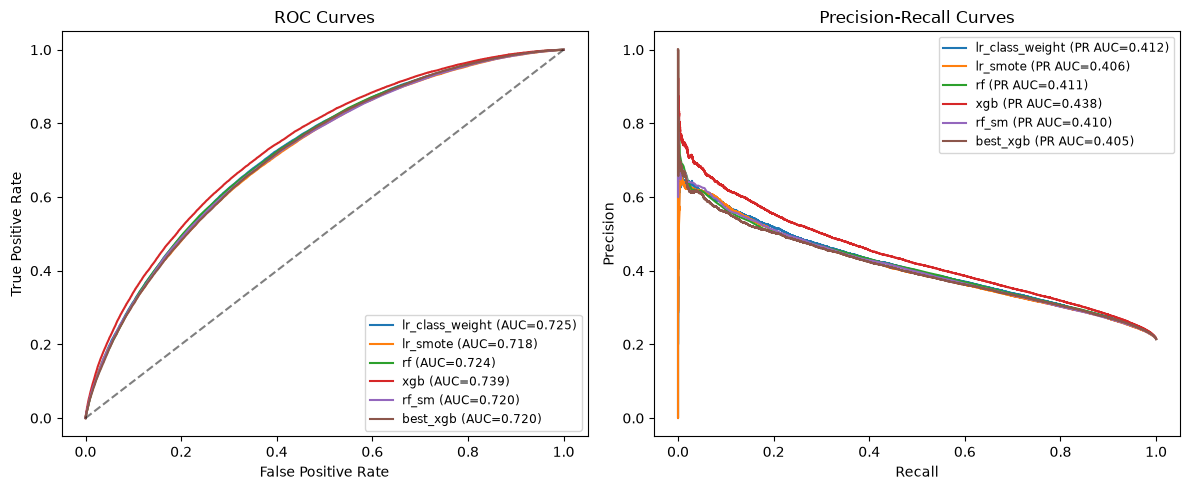

In [30]:
# Phase 4d: Calibrate thresholds, plot ROC & PR curves, and pick working points
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve, auc, f1_score, precision_score, recall_score

os.makedirs('figures', exist_ok=True)

# Collect available models and scalers
models = {}
# Logistic regressions (scaled)
if 'lr_w' in globals() and 'scaler' in globals():
    models['lr_class_weight'] = (lr_w, scaler)
if 'lr_s' in globals() and 'scaler_sm' in globals():
    models['lr_smote'] = (lr_s, scaler_sm)
# RandomForest and XGBoost (raw features)
for name in ['rf', 'xgb', 'rf_sm', 'best_xgb', 'best_xgb']:
    if name in globals():
        models[name] = (globals()[name], None)
# Also include named saved models if present
if 'rf_sm' not in models and 'rf_smote' in globals():
    models['rf_smote'] = (globals()['rf_smote'] if 'rf_smote' in globals() else None, None)

print('Models found for calibration:', list(models.keys()))

results = []
plt.figure(figsize=(12,5))
# ROC subplot
plt.subplot(1,2,1)
for label, (model, scaler_obj) in models.items():
    try:
        if scaler_obj is not None:
            X_eval = scaler_obj.transform(X_test)
        else:
            X_eval = X_test.values if hasattr(X_test, 'values') else X_test
        y_proba = model.predict_proba(X_eval)[:,1]
    except Exception as e:
        print('Skipping', label, 'due to error:', e)
        continue
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{label} (AUC={roc_auc:.3f})")
plt.plot([0,1],[0,1],'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(fontsize='small')

# PR subplot
plt.subplot(1,2,2)
for label, (model, scaler_obj) in models.items():
    try:
        if scaler_obj is not None:
            X_eval = scaler_obj.transform(X_test)
        else:
            X_eval = X_test.values if hasattr(X_test, 'values') else X_test
        y_proba = model.predict_proba(X_eval)[:,1]
    except Exception:
        continue
    precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
    pr_auc = auc(recall, precision)
    # compute F1 at thresholds
    f1_scores = (2 * precision * recall) / (precision + recall + 1e-12)
    # precision_recall_curve returns precision/recall arrays with len = len(thresholds)+1
    # align thresholds to f1 indices by ignoring last point
    f1_for_thresh = f1_scores[:-1]
    if len(f1_for_thresh) > 0:
        best_idx = np.nanargmax(f1_for_thresh)
        best_thresh = thresholds[best_idx]
        best_f1 = f1_for_thresh[best_idx]
    else:
        best_idx = None
        best_thresh = 0.5
        best_f1 = f1_scores[0]
    # metrics at default 0.5
    y_pred_default = (y_proba >= 0.5).astype(int)
    prec_def = precision_score(y_test, y_pred_default)
    rec_def = recall_score(y_test, y_pred_default)
    f1_def = f1_score(y_test, y_pred_default)
    # metrics at best_thresh
    y_pred_best = (y_proba >= best_thresh).astype(int)
    prec_best = precision_score(y_test, y_pred_best)
    rec_best = recall_score(y_test, y_pred_best)
    f1_best = f1_score(y_test, y_pred_best)
    results.append({
        'model': label,
        'roc_auc': auc(*roc_curve(y_test, y_proba)[:2]),
        'pr_auc': pr_auc,
        'default_prec': prec_def,
        'default_rec': rec_def,
        'default_f1': f1_def,
        'best_thresh': float(best_thresh),
        'best_prec': prec_best,
        'best_rec': rec_best,
        'best_f1': f1_best
    })
    plt.plot(recall, precision, label=f"{label} (PR AUC={pr_auc:.3f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend(fontsize='small')
plt.tight_layout()
fig_path = os.path.join('figures','roc_pr_curves.png')
plt.savefig(fig_path, dpi=150)
print('Saved ROC/PR plot to', fig_path)

summary_df = pd.DataFrame(results).set_index('model').sort_values('pr_auc', ascending=False)
print('\nMetrics summary (default 0.5 and best-F1 threshold):')
print(summary_df)

# Recommend model and threshold: highest PR AUC, and threshold that maximizes F1
best_model = summary_df['pr_auc'].idxmax()
recommended = summary_df.loc[best_model]
print(f"\nRecommended model for ranking (highest PR AUC): {best_model}")
print('Recommended working threshold (best-F1):', recommended['best_thresh'])

# Save summary
summary_df.to_csv('figures/model_threshold_summary.csv')
print('Saved threshold summary to figures/model_threshold_summary.csv')


Calibrating probabilities using Platt sigmoid (CalibratedClassifierCV, cv=3)


c:\loan-default-risk-predictor\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:47:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\loan-default-risk-predictor\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:47:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\loan-default-risk-predictor\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:47:36] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Saved calibrated model to models/xgb_calibrated_sigmoid.pkl
Calibrated XGB ROC AUC: 0.7424, PR AUC: 0.4429
Best F1 on test set = 0.4736 at threshold = 0.24644936516445318
roc_auc         0.742407
pr_auc          0.442907
default_prec    0.601611
default_rec     0.143857
default_f1      0.232193
best_thresh     0.246449
best_prec       0.385643
best_rec        0.613404
best_f1         0.473561
dtype: float64
Saved final model metadata to models/xgb_final_metadata.json
Saved calibration plot to figures\xgb_calibration.png
Updated figures/model_threshold_summary.csv


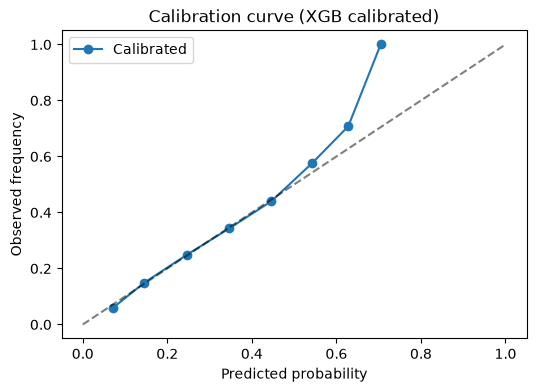

In [31]:
# Phase 4e: Probability calibration (Platt/sigmoid) on chosen XGBoost, evaluate and save calibrated model + wrapper
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
import matplotlib.pyplot as plt
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
import os

os.makedirs('figures', exist_ok=True)

# Select the XGBoost model we used for ranking (class-weight XGBoost `xgb`)
if 'xgb' not in globals():
    raise RuntimeError('xgb model not found in kernel. Run the baseline XGBoost cell first.')

base_model = xgb

print('Calibrating probabilities using Platt sigmoid (CalibratedClassifierCV, cv=3)')
calibrator = CalibratedClassifierCV(base_model, method='sigmoid', cv=3)
calibrator.fit(X_train, y_train)

# Save calibrated model
joblib.dump(calibrator, 'models/xgb_calibrated_sigmoid.pkl')
print('Saved calibrated model to models/xgb_calibrated_sigmoid.pkl')

# Evaluate on test set
try:
    X_test_eval = X_test.values if hasattr(X_test, 'values') else X_test
    y_proba_cal = calibrator.predict_proba(X_test_eval)[:,1]
except Exception:
    # if model expects dataframe with columns, pass X_test
    X_test_eval = X_test
    y_proba_cal = calibrator.predict_proba(X_test_eval)[:,1]

roc = roc_auc_score(y_test, y_proba_cal)
pr = average_precision_score(y_test, y_proba_cal)
print(f'Calibrated XGB ROC AUC: {roc:.4f}, PR AUC: {pr:.4f}')

# Find threshold that maximizes F1 on test set
precision, recall, thresholds = precision_recall_curve(y_test, y_proba_cal)
f1_scores = (2 * precision * recall) / (precision + recall + 1e-12)
if len(f1_scores) > 1:
    f1_for_thresh = f1_scores[:-1]
    best_idx = np.nanargmax(f1_for_thresh)
    best_threshold = float(thresholds[best_idx])
    best_f1 = float(f1_for_thresh[best_idx])
else:
    best_threshold = 0.5
    best_f1 = float(f1_scores[0])

print('Best F1 on test set =', round(best_f1,4), 'at threshold =', best_threshold)

# Metrics at default 0.5 and best threshold
y_pred_def = (y_proba_cal >= 0.5).astype(int)
y_pred_best = (y_proba_cal >= best_threshold).astype(int)
metrics = {
    'roc_auc': roc,
    'pr_auc': pr,
    'default_prec': precision_score(y_test, y_pred_def),
    'default_rec': recall_score(y_test, y_pred_def),
    'default_f1': f1_score(y_test, y_pred_def),
    'best_thresh': best_threshold,
    'best_prec': precision_score(y_test, y_pred_best),
    'best_rec': recall_score(y_test, y_pred_best),
    'best_f1': f1_score(y_test, y_pred_best)
}

print(pd.Series(metrics))

# Save wrapper that applies threshold to probabilities
import json
wrapper = {
    'model_path': 'models/xgb_calibrated_sigmoid.pkl',
    'threshold': best_threshold
}
with open('models/xgb_final_metadata.json', 'w') as f:
    json.dump(wrapper, f)
print('Saved final model metadata to models/xgb_final_metadata.json')

# Calibration plot
prob_true, prob_pred = calibration_curve(y_test, y_proba_cal, n_bins=10)
plt.figure(figsize=(6,4))
plt.plot(prob_pred, prob_true, marker='o', label='Calibrated')
plt.plot([0,1],[0,1],'k--', alpha=0.5)
plt.xlabel('Predicted probability')
plt.ylabel('Observed frequency')
plt.title('Calibration curve (XGB calibrated)')
plt.legend()
cal_plot_path = os.path.join('figures','xgb_calibration.png')
plt.savefig(cal_plot_path, dpi=150)
print('Saved calibration plot to', cal_plot_path)

# Update figures summary CSV with calibrated model
summary_path = 'figures/model_threshold_summary.csv'
if os.path.exists(summary_path):
    df = pd.read_csv(summary_path, index_col=0)
else:
    df = pd.DataFrame()

cal_row = pd.Series(metrics, name='xgb_calibrated')
df.loc['xgb_calibrated'] = cal_row
df.to_csv(summary_path)
print('Updated', summary_path)


Running SHAP on 10000 rows


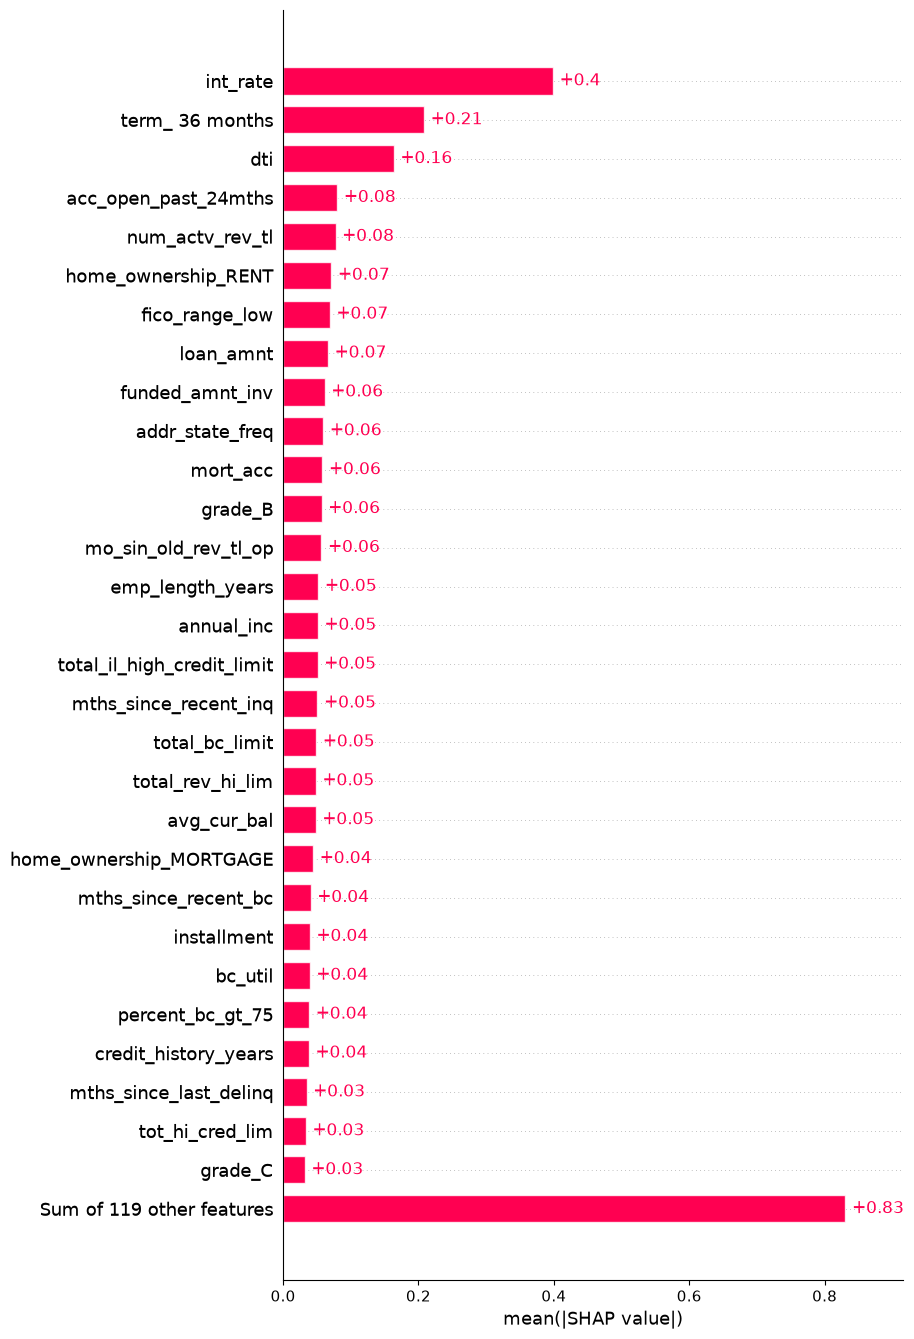

Saved figures/shap_summary.png


<Figure size 640x480 with 0 Axes>

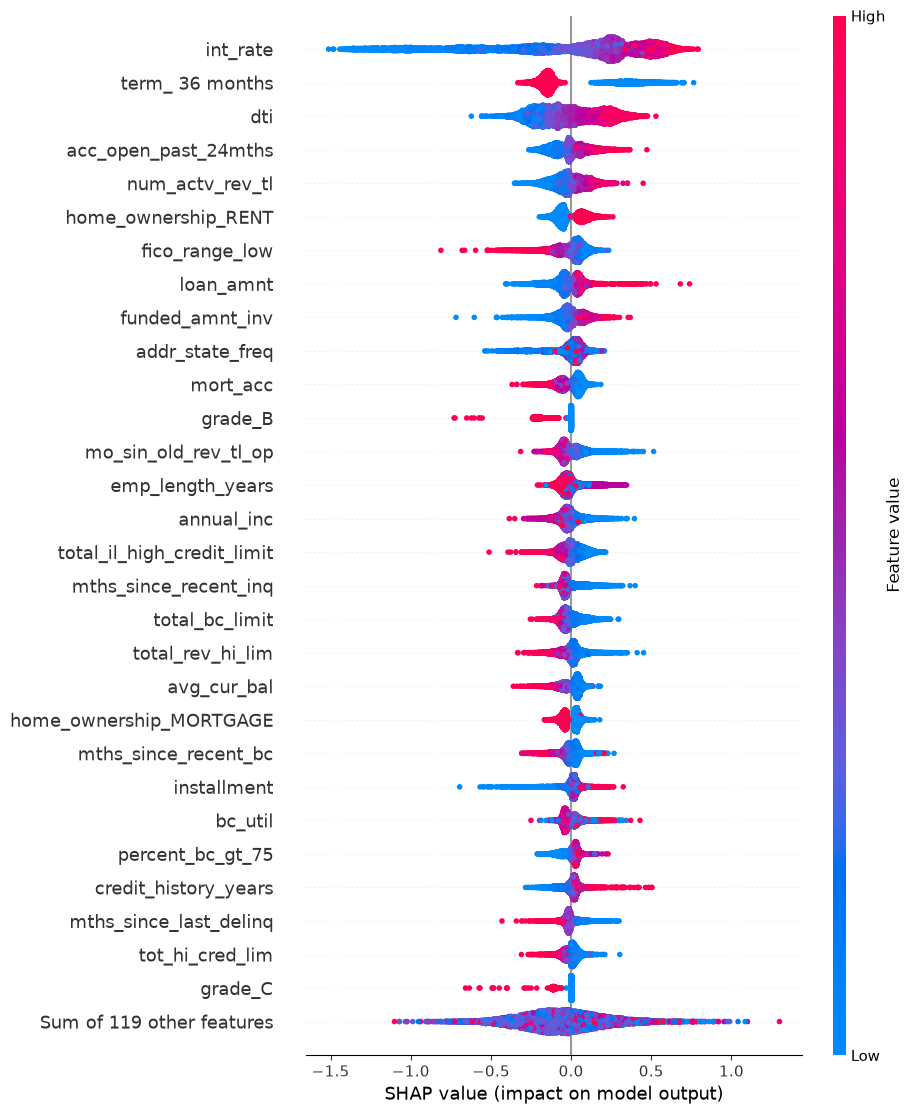

Saved figures/shap_beeswarm.png
Saved figures/shap_feature_importance.csv


<Figure size 640x480 with 0 Axes>

In [32]:
# Phase 4f: SHAP explanations (summary + beeswarm) -- sample for speed
import os
import joblib
import shap
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

os.makedirs('figures', exist_ok=True)
# Prefer saved XGBoost model, fallback to kernel objects
try:
    model = joblib.load('models/xgb_balanced.pkl')
except Exception:
    model = globals().get('xgb', globals().get('best_xgb'))
if model is None:
    raise RuntimeError('XGBoost model not found in models/ or kernel scope')
# Use X_test from kernel; sample up to 10k rows to keep SHAP fast
if 'X_test' not in globals():
    raise RuntimeError('X_test not found in kernel scope; run Phase 4 splitting first')
X_ev = X_test if isinstance(X_test, (pd.DataFrame,)) else pd.DataFrame(X_test)
n_sample = min(10000, len(X_ev))
if len(X_ev) > n_sample:
    X_s = X_ev.sample(n=n_sample, random_state=42)
else:
    X_s = X_ev.copy()
# Ensure columns are consistent for SHAP
X_s = X_s.reset_index(drop=True)
print('Running SHAP on', len(X_s), 'rows')
# Create Tree explainer for XGBoost; falls back to generic Explainer
try:
    expl = shap.Explainer(model)
    sv = expl(X_s)
except Exception:
    expl = shap.TreeExplainer(model)
    sv_vals = expl.shap_values(X_s)
    # wrap into a simple object for older shap APIs
    class _SV:
        def __init__(self, values):
            self.values = values
    sv = _SV(sv_vals)
# Summary bar (mean(|SHAP|))
plt.figure(figsize=(8,6))
try:
    shap.plots.bar(sv, max_display=30)
    plt.tight_layout()
    plt.savefig('figures/shap_summary.png', dpi=150)
except Exception:
    plt.clf()
    shap.summary_plot(sv.values if hasattr(sv, 'values') else sv, X_s, show=False, max_display=30)
    plt.tight_layout()
    plt.savefig('figures/shap_summary.png', dpi=150)
print('Saved figures/shap_summary.png')
# Beeswarm / dot plot
plt.figure(figsize=(8,6))
try:
    shap.plots.beeswarm(sv, max_display=30)
    plt.tight_layout()
    plt.savefig('figures/shap_beeswarm.png', dpi=150)
except Exception:
    plt.clf()
    shap.summary_plot(sv.values if hasattr(sv, 'values') else sv, X_s, show=False, plot_type='dot', max_display=30)
    plt.tight_layout()
    plt.savefig('figures/shap_beeswarm.png', dpi=150)
print('Saved figures/shap_beeswarm.png')
# Feature importance (mean absolute SHAP) to CSV
if hasattr(sv, 'values'):
    arr = np.abs(sv.values).mean(axis=0)
else:
    arr = np.abs(sv).mean(axis=0)
feat_imp = pd.DataFrame({'feature': X_s.columns, 'mean_abs_shap': arr})
feat_imp = feat_imp.sort_values('mean_abs_shap', ascending=False)
feat_imp.to_csv('figures/shap_feature_importance.csv', index=False)
print('Saved figures/shap_feature_importance.csv')